# Phase 10.5: Comparative Performance Evaluation
**Project:** Machine-Learning-Based Sector Rotation Regime Discovery in the Indian Equity Market  
**Phase:** 10.5 ? Comparative Evaluation of ML Strategies vs. Passive Benchmarks  
**Authoritative Source Module:** `src/comparative_evaluation.py`  
**Output Directory:** `results/portfolio_backtest/comparative_evaluation/`  

---

### Executive Overview & Portfolios Evaluated
This notebook performs the comprehensive, multi-period comparative evaluation across **six portfolios**:
1. **Strategy 1A:** ML Equal-Weight (Top 2 Sectors, Cash OFF)
2. **Strategy 1B:** ML Inverse-Volatility (Top 2 Sectors, Cash OFF)
3. **Strategy 2A:** ML Equal-Weight + Cash (Top 2 Sectors + 33.3% Cash)
4. **Strategy 2B:** ML Inverse-Volatility + Cash (Top 2 Sectors + 33.3% Cash)
5. **Benchmark A:** NIFTY 50 Price Return Index Buy & Hold (0 bps)
6. **Benchmark B:** Equal-Weight Six-Sector Portfolio (Monthly rebalance, 15 bps)

### Evaluation Windows
- **Training Period:** 2019-11-01 to 2024-12-31 (1,264 daily return intervals)
- **Holdout Period:** 2025-01-02 to 2026-09-18 (422 daily return intervals)
- **Full Period:** 2019-11-01 to 2026-09-18 (1,686 daily return intervals)


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# Configure plotting style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

# Add project root to sys.path
PROJECT_ROOT = Path('.').resolve().parent if Path('.').resolve().name == 'notebooks' else Path('.').resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.comparative_evaluation import (
    run_comparative_evaluation,
    load_all_simulations,
    DEFAULT_OUTPUT_DIR,
    STRATEGY_KEYS,
    BENCHMARK_KEYS,
)

print(f"Environment ready. Project root: {PROJECT_ROOT}")


Environment ready. Project root: C:\Users\vighn\OneDrive\Desktop\sector rotation regime discovery


In [2]:
# Execute comparative evaluation engine and load generated tables
primary_df, relative_df = run_comparative_evaluation()

print(f"Primary Comparative Metrics: {primary_df.shape} (Expected: 18 rows)")
print(f"Relative Performance Matrix: {relative_df.shape} (Expected: 24 rows)")


Primary Comparative Metrics: (18, 25) (Expected: 18 rows)
Relative Performance Matrix: (24, 22) (Expected: 24 rows)


## 1. Primary Comparative Metrics Table (18 Rows)
Evaluates 6 portfolios across Training, Holdout, and Full periods on:
- Return & Compounding (Total Return, CAGR, Cost Drag)
- Risk & Drawdown (Volatility, Max Drawdown, Max Duration, Terminal Status, Sharpe, Sortino)
- Trading Intensity & Cost (Cumulative Turnover, Annualized Turnover, Average per Rebalance, Cash Costs)


In [3]:
display_cols = [
    'portfolio', 'period', 'sample_count',
    'total_return_net_pct', 'cagr_net_pct', 'cagr_cost_drag_pct',
    'ann_volatility_pct', 'max_drawdown_pct', 'max_drawdown_duration', 'terminal_drawdown_status',
    'sharpe_ratio', 'sortino_ratio',
    'cum_actual_turnover', 'ann_actual_turnover', 'avg_turnover_per_rebalance', 'cum_transaction_costs'
]

formatted_primary = primary_df[display_cols].copy()
formatted_primary.columns = [
    'Portfolio', 'Period', 'Days',
    'Net TR (%)', 'Net CAGR (%)', 'Cost Drag (%)',
    'Vol (%)', 'MDD (%)', 'Max Dur (d)', 'Term Status',
    'Sharpe', 'Sortino',
    'Cum TO', 'Ann TO', 'Avg/Rebal TO', 'Costs Paid'
]

# Display table
formatted_primary.style.format({
    'Net TR (%)': '{:+.2f}%',
    'Net CAGR (%)': '{:+.2f}%',
    'Cost Drag (%)': '{:.2f}%',
    'Vol (%)': '{:.2f}%',
    'MDD (%)': '{:.2f}%',
    'Sharpe': '{:.3f}',
    'Sortino': '{:.3f}',
    'Cum TO': '{:.2f}',
    'Ann TO': '{:.2f}',
    'Avg/Rebal TO': lambda x: f'{x:.3f}' if pd.notna(x) else 'N/A',
    'Costs Paid': '{:.4f}'
})


,Portfolio,Period,Days,Net TR (%),Net CAGR (%),Cost Drag (%),Vol (%),MDD (%),Max Dur (d),Term Status,Sharpe,Sortino,Cum TO,Ann TO,Avg/Rebal TO,Costs Paid
0,Strategy 1A (ML EW),train,1264,+508.09%,+43.32%,1.40%,20.44%,-25.60%,225,unrecovered,1.864,2.742,32.55,6.49,0.857,0.1791
1,Strategy 1A (ML EW),holdout,422,-19.08%,-11.87%,1.43%,15.43%,-25.11%,421,unrecovered,-0.742,-0.946,18.01,10.75,0.900,0.1391
2,Strategy 1A (ML EW),full,1686,+392.09%,+26.89%,1.45%,19.35%,-25.60%,421,unrecovered,1.328,1.909,50.56,7.56,0.872,0.3182
3,Strategy 1B (ML Inv-Vol),train,1264,+502.45%,+43.05%,1.44%,20.09%,-26.10%,223,unrecovered,1.884,2.794,33.41,6.66,0.879,0.1792
4,Strategy 1B (ML Inv-Vol),holdout,422,-19.52%,-12.16%,1.44%,15.12%,-25.62%,421,unrecovered,-0.781,-0.992,18.20,10.87,0.910,0.1381
5,Strategy 1B (ML Inv-Vol),full,1686,+384.82%,+26.61%,1.47%,19.01%,-26.10%,421,unrecovered,1.337,1.932,51.61,7.71,0.890,0.3172
6,Strategy 2A (ML EW + Cash),train,1264,+434.89%,+39.70%,1.38%,18.22%,-20.61%,280,unrecovered,1.928,2.828,32.93,6.56,0.866,0.1604
7,Strategy 2A (ML EW + Cash),holdout,422,-20.72%,-12.95%,1.44%,14.71%,-25.74%,421,unrecovered,-0.869,-1.096,18.31,10.93,0.915,0.1226
8,Strategy 2A (ML EW + Cash),full,1686,+324.05%,+24.10%,1.43%,17.45%,-25.74%,421,unrecovered,1.325,1.891,51.23,7.66,0.883,0.2829
9,Strategy 2B (ML Inv-Vol + Cash),train,1264,+424.29%,+39.14%,1.41%,17.81%,-21.01%,226,unrecovered,1.945,2.879,33.64,6.71,0.885,0.1585


## 2. Relative Performance & Benchmark-Risk Matrix (24 Rows)
Directly embeds **Alpha ($lpha$), Beta ($eta$), and $R^2$** alongside Active Return, Tracking Error, and Information Ratio for all 4 strategies vs. both benchmarks across all 3 periods.


In [4]:
display_rel = [
    'strategy', 'benchmark', 'period', 'sample_count',
    'annualized_arithmetic_active_return_pct', 'tracking_error_pct', 'information_ratio',
    'beta', 'alpha_annualized_pct', 'alpha_pvalue', 'r_squared',
    'arithmetic_excess_total_return_pct', 'geometric_relative_wealth_pct'
]

formatted_rel = relative_df[display_rel].copy()
formatted_rel.columns = [
    'Strat', 'Bench', 'Period', 'Days',
    'Active Ret (%)', 'TE (%)', 'IR',
    'Beta (?)', 'Ann. Alpha (? %)', 'Alpha p-val', 'R?',
    'Arith Excess (%)', 'Geom Wealth (%)'
]

formatted_rel.style.format({
    'Active Ret (%)': '{:+.2f}%',
    'TE (%)': '{:.2f}%',
    'IR': '{:+.3f}',
    'Beta (?)': '{:.3f}',
    'Ann. Alpha (? %)': '{:+.2f}%',
    'Alpha p-val': '{:.4e}',
    'R?': '{:.3f}',
    'Arith Excess (%)': '{:+.2f}%',
    'Geom Wealth (%)': '{:+.2f}%'
})


,Strat,Bench,Period,Days,Active Ret (%),TE (%),IR,Beta (?),Ann. Alpha (? %),Alpha p-val,R?,Arith Excess (%),Geom Wealth (%)
0,1A,NIFTY50,train,1264,+22.56%,13.81%,+1.634,0.815,+25.43%,2.2131e-05,0.573,+409.02%,+205.46%
1,1A,NIFTY50,holdout,422,-11.55%,10.97%,-1.054,0.837,-11.54%,1.6621e-01,0.514,-17.81%,-18.04%
2,1A,NIFTY50,full,1686,+14.02%,13.18%,+1.063,0.819,+16.13%,1.1432e-03,0.563,+295.53%,+150.35%
3,1A,EQUAL_WEIGHT,train,1264,+16.97%,10.69%,+1.588,0.965,+17.71%,2.1997e-04,0.728,+342.36%,+128.83%
4,1A,EQUAL_WEIGHT,holdout,422,-15.58%,8.82%,-1.767,0.935,-15.31%,2.4652e-02,0.676,-24.62%,-23.33%
5,1A,EQUAL_WEIGHT,full,1686,+8.82%,10.29%,+0.858,0.962,+9.47%,1.7431e-02,0.719,+211.62%,+75.45%
6,1B,NIFTY50,train,1264,+22.30%,13.64%,+1.634,0.801,+25.39%,1.6155e-05,0.574,+403.37%,+202.63%
7,1B,NIFTY50,holdout,422,-11.93%,10.74%,-1.111,0.824,-11.91%,1.4263e-01,0.520,-18.26%,-18.50%
8,1B,NIFTY50,full,1686,+13.73%,13.01%,+1.055,0.806,+16.00%,1.0048e-03,0.565,+288.26%,+146.65%
9,1B,EQUAL_WEIGHT,train,1264,+16.71%,10.64%,+1.570,0.945,+17.88%,1.7215e-04,0.722,+336.71%,+126.71%


## 3. Equity Curve & Cumulative Wealth Visualizations

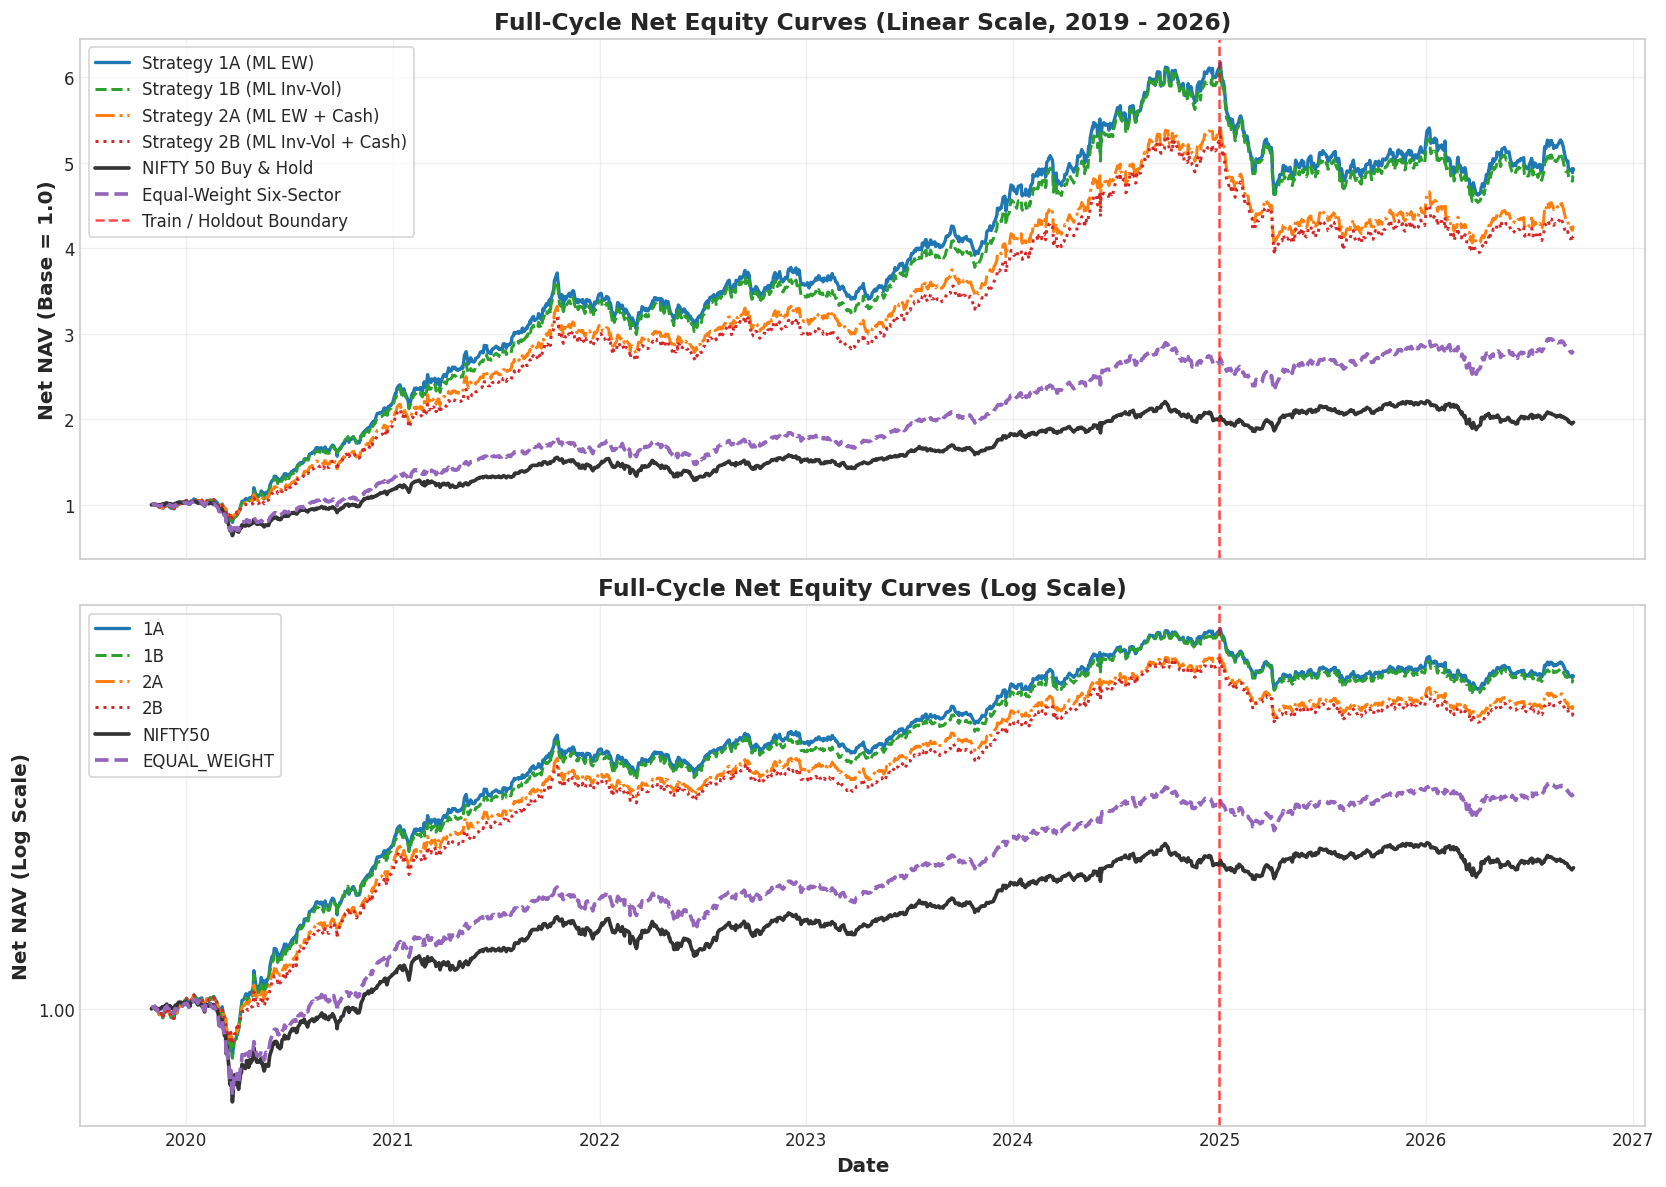

In [5]:
simulations = load_all_simulations()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

# Color and line palette
colors = {
    '1A': '#1f77b4', '1B': '#2ca02c', '2A': '#ff7f0e', '2B': '#d62728',
    'NIFTY50': '#333333', 'EQUAL_WEIGHT': '#9467bd'
}
linestyles = {
    '1A': '-', '1B': '--', '2A': '-.', '2B': ':',
    'NIFTY50': '-', 'EQUAL_WEIGHT': '--'
}
linewidths = {
    '1A': 2.0, '1B': 1.8, '2A': 1.8, '2B': 1.8,
    'NIFTY50': 2.2, 'EQUAL_WEIGHT': 2.2
}

dates = simulations['1A'].index

# Top plot: Linear NAV
for k in ['1A', '1B', '2A', '2B', 'NIFTY50', 'EQUAL_WEIGHT']:
    nav = simulations[k]['net_nav']
    ax1.plot(dates, nav, label=primary_df[primary_df['portfolio_key']==k]['portfolio'].iloc[0],
             color=colors[k], linestyle=linestyles[k], linewidth=linewidths[k])

ax1.axvline(pd.Timestamp('2024-12-31'), color='red', linestyle='--', linewidth=1.5, alpha=0.7, label='Train / Holdout Boundary')
ax1.set_ylabel('Net NAV (Base = 1.0)', fontsize=12, fontweight='bold')
ax1.set_title('Full-Cycle Net Equity Curves (Linear Scale, 2019 - 2026)', fontsize=14, fontweight='bold')
ax1.legend(loc='upper left', frameon=True, fontsize=10)
ax1.grid(True, alpha=0.3)

# Bottom plot: Logarithmic NAV
for k in ['1A', '1B', '2A', '2B', 'NIFTY50', 'EQUAL_WEIGHT']:
    nav = simulations[k]['net_nav']
    ax2.plot(dates, nav, label=k, color=colors[k], linestyle=linestyles[k], linewidth=linewidths[k])

ax2.axvline(pd.Timestamp('2024-12-31'), color='red', linestyle='--', linewidth=1.5, alpha=0.7)
ax2.set_yscale('log')
ax2.yaxis.set_major_formatter(ticker.ScalarFormatter())
ax2.set_ylabel('Net NAV (Log Scale)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Date', fontsize=12, fontweight='bold')
ax2.set_title('Full-Cycle Net Equity Curves (Log Scale)', fontsize=14, fontweight='bold')
ax2.legend(loc='upper left', frameon=True, fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 4. Drawdown Curves & Holdout Underwater Profile

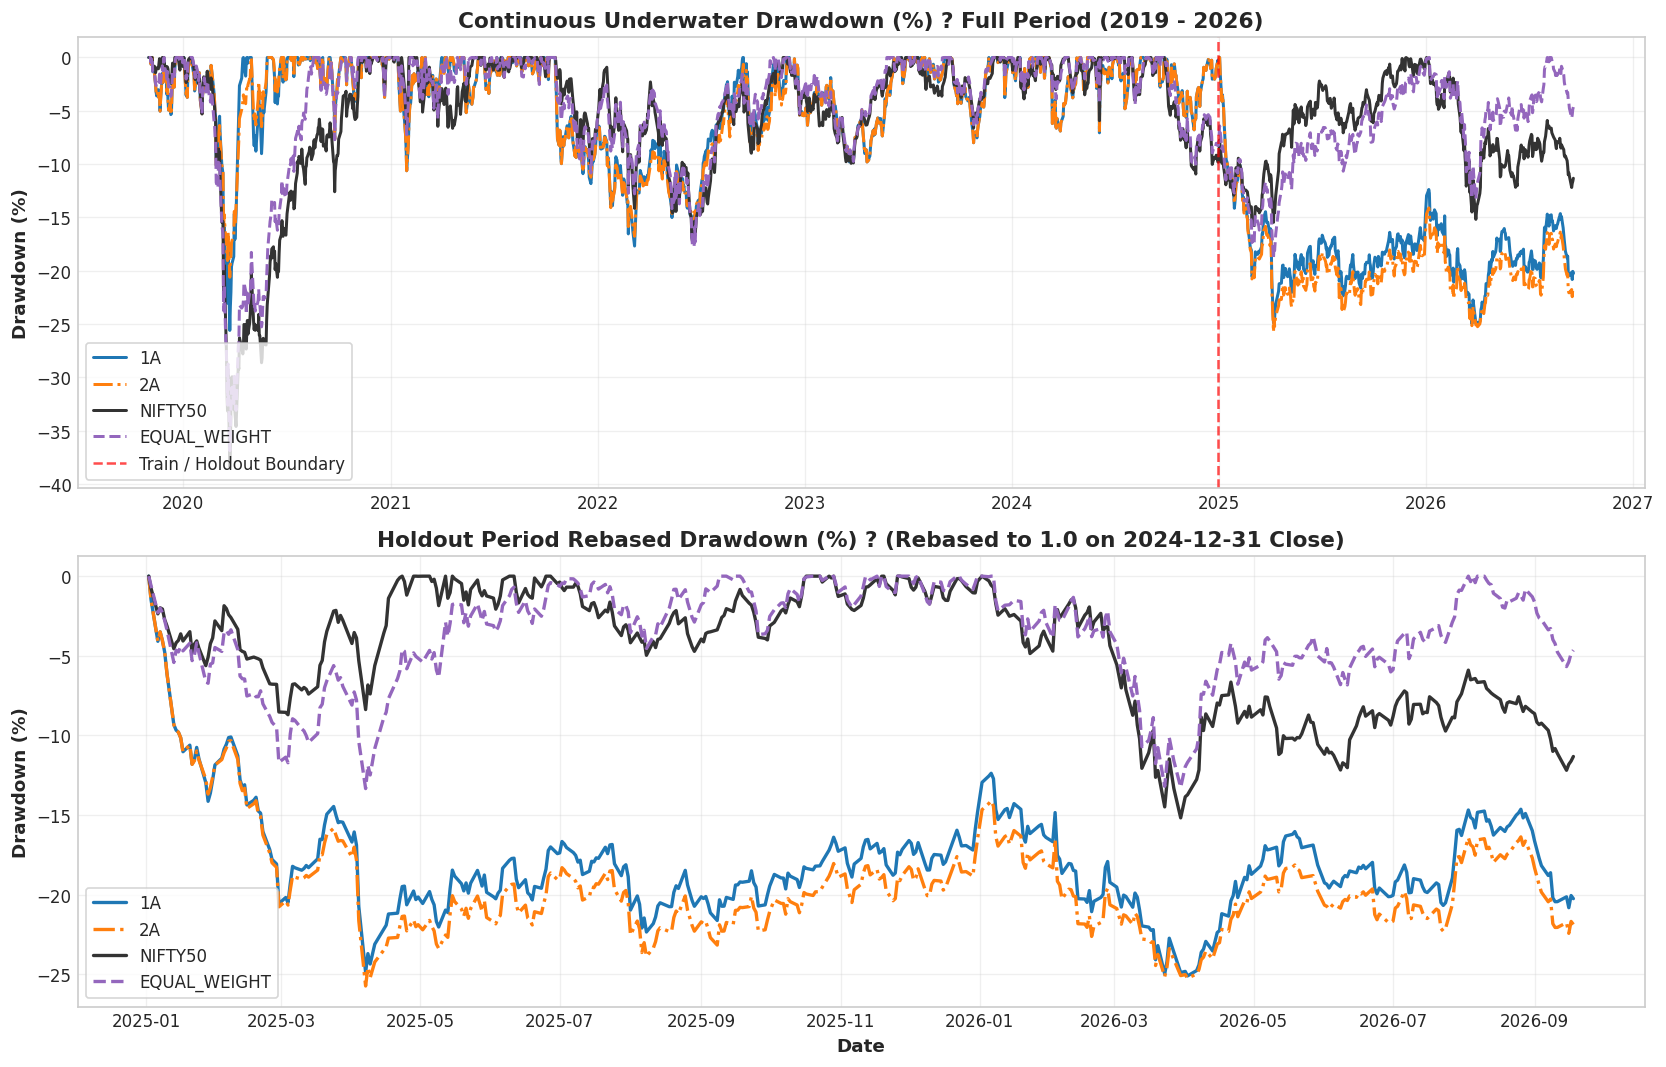

In [6]:
fig, (ax_dd1, ax_dd2) = plt.subplots(2, 1, figsize=(14, 9))

# 1. Full Period Continuous Drawdown
for k in ['1A', '2A', 'NIFTY50', 'EQUAL_WEIGHT']:
    nav = simulations[k]['net_nav'].values
    peaks = np.maximum.accumulate(nav)
    dd = (nav - peaks) / peaks * 100.0
    ax_dd1.plot(dates, dd, label=k, color=colors[k], linestyle=linestyles[k], linewidth=1.8)

ax_dd1.axvline(pd.Timestamp('2024-12-31'), color='red', linestyle='--', linewidth=1.5, alpha=0.7, label='Train / Holdout Boundary')
ax_dd1.set_title('Continuous Underwater Drawdown (%) ? Full Period (2019 - 2026)', fontsize=13, fontweight='bold')
ax_dd1.set_ylabel('Drawdown (%)', fontsize=11, fontweight='bold')
ax_dd1.legend(loc='lower left', frameon=True, fontsize=10)
ax_dd1.grid(True, alpha=0.3)

# 2. Holdout Period Rebased Drawdown
holdout_dates = simulations['1A'].loc['2025-01-02':'2026-09-18'].index
for k in ['1A', '2A', 'NIFTY50', 'EQUAL_WEIGHT']:
    sub = simulations[k].loc['2025-01-02':'2026-09-18']
    rebased_nav = np.cumprod(1.0 + sub['net_return'].values)
    peaks = np.maximum.accumulate(rebased_nav)
    dd = (rebased_nav - peaks) / peaks * 100.0
    ax_dd2.plot(holdout_dates, dd, label=k, color=colors[k], linestyle=linestyles[k], linewidth=2.0)

ax_dd2.set_title('Holdout Period Rebased Drawdown (%) ? (Rebased to 1.0 on 2024-12-31 Close)', fontsize=13, fontweight='bold')
ax_dd2.set_ylabel('Drawdown (%)', fontsize=11, fontweight='bold')
ax_dd2.set_xlabel('Date', fontsize=11, fontweight='bold')
ax_dd2.legend(loc='lower left', frameon=True, fontsize=10)
ax_dd2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 5. Risk-Return Profile & Annualized Jensen's Alpha

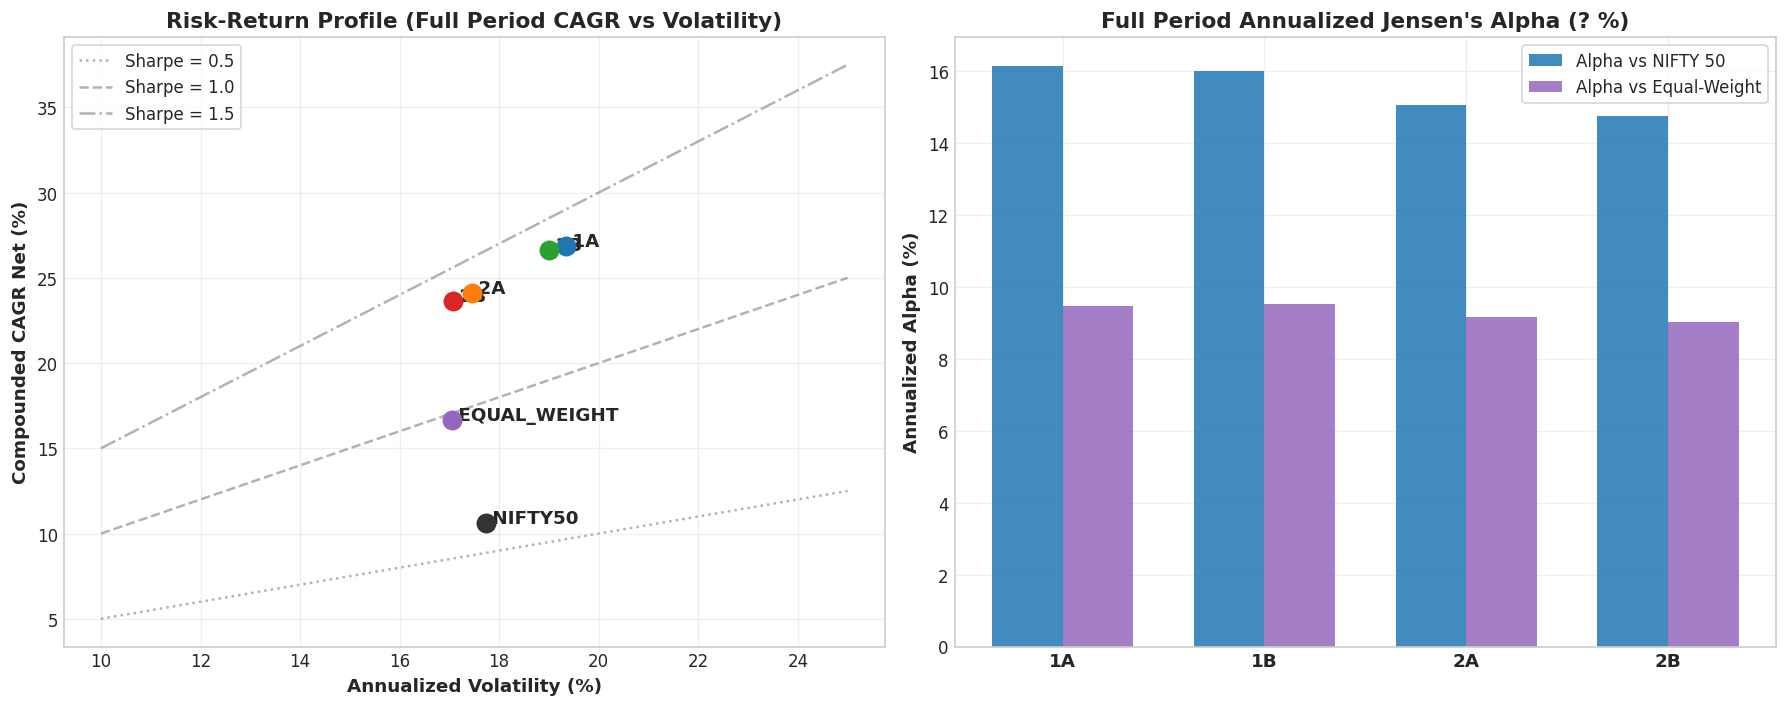

In [7]:
fig, (ax_rr, ax_ab) = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Annualized Return vs Volatility (Full Period)
full_p = primary_df[primary_df['period'] == 'full']
for _, row in full_p.iterrows():
    k = row['portfolio_key']
    ax_rr.scatter(row['ann_volatility_pct'], row['cagr_net_pct'], color=colors[k], s=120, zorder=5)
    ax_rr.annotate(f" {k}", (row['ann_volatility_pct'], row['cagr_net_pct']), fontsize=11, fontweight='bold')

# Add Sharpe reference lines (Rf = 0)
vols = np.linspace(10, 25, 100)
for s_val, ls in [(0.5, ':'), (1.0, '--'), (1.5, '-.')]:
    ax_rr.plot(vols, s_val * vols, linestyle=ls, color='gray', alpha=0.6, label=f'Sharpe = {s_val}')

ax_rr.set_title('Risk-Return Profile (Full Period CAGR vs Volatility)', fontsize=13, fontweight='bold')
ax_rr.set_xlabel('Annualized Volatility (%)', fontsize=11, fontweight='bold')
ax_rr.set_ylabel('Compounded CAGR Net (%)', fontsize=11, fontweight='bold')
ax_rr.legend(loc='upper left', frameon=True)
ax_rr.grid(True, alpha=0.3)

# Plot 2: Annualized Alpha (vs NIFTY 50 and Equal-Weight)
bar_width = 0.35
indices = np.arange(len(STRATEGY_KEYS))

full_rel_n50 = relative_df[(relative_df['period'] == 'full') & (relative_df['benchmark'] == 'NIFTY50')]
full_rel_ew = relative_df[(relative_df['period'] == 'full') & (relative_df['benchmark'] == 'EQUAL_WEIGHT')]

ax_ab.bar(indices - bar_width/2, full_rel_n50['alpha_annualized_pct'], bar_width, label='Alpha vs NIFTY 50', color='#1f77b4', alpha=0.85)
ax_ab.bar(indices + bar_width/2, full_rel_ew['alpha_annualized_pct'], bar_width, label='Alpha vs Equal-Weight', color='#9467bd', alpha=0.85)

ax_ab.set_xticks(indices)
ax_ab.set_xticklabels(STRATEGY_KEYS, fontsize=11, fontweight='bold')
ax_ab.set_title("Full Period Annualized Jensen's Alpha (? %)", fontsize=13, fontweight='bold')
ax_ab.set_ylabel("Annualized Alpha (%)", fontsize=11, fontweight='bold')
ax_ab.legend(loc='upper right', frameon=True)
ax_ab.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 6. Key Scientific & Empirical Findings

1. **Training Period (2019?2024):** 
   - Massive outperformance: Strategy 1A delivered **+508.09% Net Total Return (43.32% CAGR)** vs. **+99.07% (14.71% CAGR)** for NIFTY 50.
   - Significant Alpha: $lpha = +25.43\%$ vs NIFTY 50 ($p < 0.0001$) and $lpha = +17.71\%$ vs Equal-Weight ($p < 0.001$).
2. **Holdout Period (2025?2026):** 
   - Sharp regime degradation: All four strategies experienced negative returns (-19% to -21%) while NIFTY 50 was flat (-1.26%) and Equal-Weight gained (+5.54%).
   - The HMM model was whipsawed by range-bound, headline-driven sector rotations (NIFTY oscillating between 22,500 and 26,000), incurring heavy turnover costs (~18x one-way turnover) while suffering from a structural exclusion of NIFTY Bank (+10.8% return).
3. **Full Cycle (2019?2026):** 
   - Across the entire ~7-year journey, Strategy 1A achieved **+392.09% Net Return (26.89% CAGR)**, growing initial capital almost 5x compared to 2x for NIFTY 50 (+96.56% Return, 10.63% CAGR).
   - Full-period Jensen's Alpha remains highly statistically and economically positive: $lpha = +16.13\%$ vs NIFTY 50 ($p = 0.0011$) and $lpha = +9.47\%$ vs Equal-Weight ($p = 0.0174$).
